### Initialize instrumentation

In [1]:
# import packages
from Equipments import BNC575, Weeder, SR400, MCBOX, Andor, LeCroyScope
from Equipments.MCBOX import generate_test_voltages
from DataProcessing.Plot import PlotSaver
from DataProcessing import Readout

import numpy as np
import pyvisa
import time
import matplotlib.pyplot as plt
from DataProcessing.StarkCalibrate import symmetry_search
# from scipy.signal import find_peaks

from matplotlib import rcParams
rcParams['font.family'] = 'sans serif'
rcParams['mathtext.fontset'] = 'stix'
rcParams['axes.unicode_minus'] = False
rcParams.update({
	'font.size': 14,
	'axes.titlesize': 14,
	'axes.labelsize': 14,
	'xtick.labelsize': 14,
	'ytick.labelsize': 14,
	'legend.fontsize': 14,
	'figure.titlesize': 14,
	'legend.frameon': False,
})

In [2]:
# set up readout and plotting
ps = PlotSaver("X:/migratedData/Rydberg_QIS/data")

In [3]:
# open list of available instruments
rm = pyvisa.ResourceManager()
print(rm.list_resources())

('ASRL1::INSTR', 'ASRL2::INSTR', 'ASRL3::INSTR', 'ASRL4::INSTR', 'ASRL5::INSTR', 'ASRL6::INSTR', 'ASRL7::INSTR', 'ASRL11::INSTR', 'GPIB0::3::INSTR', 'GPIB0::9::INSTR', 'GPIB0::23::INSTR', 'TCPIP0::169.254.110.10::inst0::INSTR', 'USB0::0x1313::0x807B::241023118::0::INSTR')


In [4]:
# connect to BNC 575 pulse generator (for controlling experimental time sequence)
bnc575 = BNC575.BNC575("GPIB0::9::INSTR")

In [5]:
# connect to SR400 gated photon counter (for performing Rydberg atom counting)
sr400 = SR400.SR400("GPIB0::23::INSTR", timeout = 5000)

In [6]:
# connect to WeederTech WTMCD-M driver (for 480 stepper motor)
weeder = Weeder.Weeder("ASRL1::INSTR")

In [7]:
# connect to MC USB-3114 (for compensation voltages)
mcbox = MCBOX.MCBOX(find_device = "USB-3114")

USB-3114 found.
Board number: 0


### Define timing sequence, set up photon counter

In [47]:
vset = np.array([0.4, -0.05, -0.015])
mcbox.set_voltage_Nchan(channels = [0,1,6,7,10,11], 
                        voltages = [0,-vset[2],vset[1],-vset[1],vset[0],-vset[0]], bipolar = True)

Channel 0 has been set to 0 V.
Channel 1 has been set to 0.015 V.
Channel 6 has been set to -0.05 V.
Channel 7 has been set to 0.05 V.
Channel 10 has been set to 0.4 V.
Channel 11 has been set to -0.4 V.
Voltages successfully set.


In [8]:
############################## current pulsed sequence ##############################
pulse_arrangement = [["A", 1300e-6, 0, 2, 1],                 # MOT AOM
                     [["B", 15e-6, 40e-6, 2, 1],              # 780 AOM
                     ["C", 15e-6, 40e-6, 6, -1]],             # 480 switch
                     [["D", 26e-6, 0, 6, 1],                  # AWG
                     ["E", 26e-6, 0, 6, 1]],                  # SR400 gated counter
                    ]

T = 1600e-6  # sequence period; changed from 1500 us

In [9]:
# set up gated photon counter
cycle_number = 30

# photon counter gate width and delay
gate_width = 130e-6 # changed from 20 us
gate_delay = 3e-6  # changed from 3 us

# stepper motor slope (for blue laser)
freq_factor = 129 * 2 # kHz

notes = {"gate_width": gate_width, "gate_delay": gate_delay, "states": "70 D"}

In [10]:
# set up the photon counter; count_preset changed from 100 us
sr400.counter_set(count_mode = "INDEPENDENT", count_preset = 140e-6, count_period_num = cycle_number, 
                  dwell = 0, sourceA = "INPUT1", sourceB = "INPUT2", gate_A_mode = "FIXED",
                  gate_A_delay = gate_delay, gate_A_width = gate_width, gate_B_mode = "CW")

------------------------------------------------------------
The photon counter is now set to:

Counting Mode: INDEPENDENT
T Input: 10MHz
T Preset: 0.0001s
Period number: 30
Dwell time: External
Counter A source: INPUT1
Counter B source: INPUT2

The gate A is set to:

Delay: 3.000E-6
Width: 130.0E-6


The gate B is set to: CW
------------------------------------------------------------


In [11]:
notes["bnc575 T0"] = bnc575.clock_set(period = T, mode = "CONTINUOUS")
notes["bnc575 pulses"] = bnc575.pulse_sequence_setup(pulse_arrangement)

------------------------------------------------------------
The global clock is set to:
Mode: NORM
Period: 1.60e-03s
Pulses number: N/A
------------------------------------------------------------
[['A', 0.0013, 0, 2, 1], ['B', 1.5e-05, 0.00134, 2, 1], ['C', 1.5e-05, 0.00134, 6, -1], ['D', 2.6e-05, 0.001355, 6, 1], ['E', 2.6e-05, 0.001355, 6, 1]]
------------------------------------------------------------
The channel A is set to:
Width: 1.3000e-03s
Delay: 0.0000e+00s
Synchronize to: T0
Out: 2.00

Output timers:
HGFEDCBA
00000001
------------------------------------------------------------
------------------------------------------------------------
The channel B is set to:
Width: 1.5000e-05s
Delay: 1.3400e-03s
Synchronize to: T0
Out: 2.00

Output timers:
HGFEDCBA
00000010
------------------------------------------------------------
------------------------------------------------------------
The channel C is set to:
Width: 1.5000e-05s
Delay: 1.3400e-03s
Synchronize to: T0
Out: 6.00



In [12]:
bnc575.start_pulses()

### Find the Rydberg resonance

In [14]:
# find current stepper motor position
weeder.position(header = "A", query = True)

'A4200'

In [26]:
# begin stepper motor at initial position 6000, then move it out to increase the laser frequency
weeder.move("A", position = 4000, progress = True)

start at 4200 --> 4000.0 --> 4000
Old position: 4200
New position: 4000


In [ ]:
# used to move motor incrementally to zero in on the location of a resonance
weeder.advance(header = "A", num_step = 100)

### Stark maps and field zeroing

#### 1D map (frequency scan only)

In [48]:
# set up scanning parameters
center = 4000
stride = 2
half_width = 400

# scan list gneration
x_list = np.arange(2* half_width/stride)

In [49]:
# scan over the blue laser frequency, record photon counts (averaged over 30 shots)

# when scan begins, we overshoot on the initial position and then move motor to real start position to release the band tension and gear margin
start_position = center - half_width
weeder.move(header = "A", position = start_position - 100)
weeder.move(header = "A", position = start_position)

results = []
# s = time.perf_counter()
for idx in x_list:
    print(f"Now checking step: {idx}", end = "\r", flush = True)
    sr400.count_reset()
    result = np.mean(sr400.read_entire_counts(counter = "A", length = cycle_number))
    results.append(result)
    for i in range(stride):
        weeder.step("A", "+")
    time.sleep(0.1)
    
# e = time.perf_counter()
# print('Time elapsed: {} seconds'.format(e-s))

start at 4300 --> 3500.0 --> 3500
Old position: 4300
New position: 3500
start at 3500 --> 3600.0 --> 3600
Old position: 3500
New position: 3600
Now checking step: 399.0

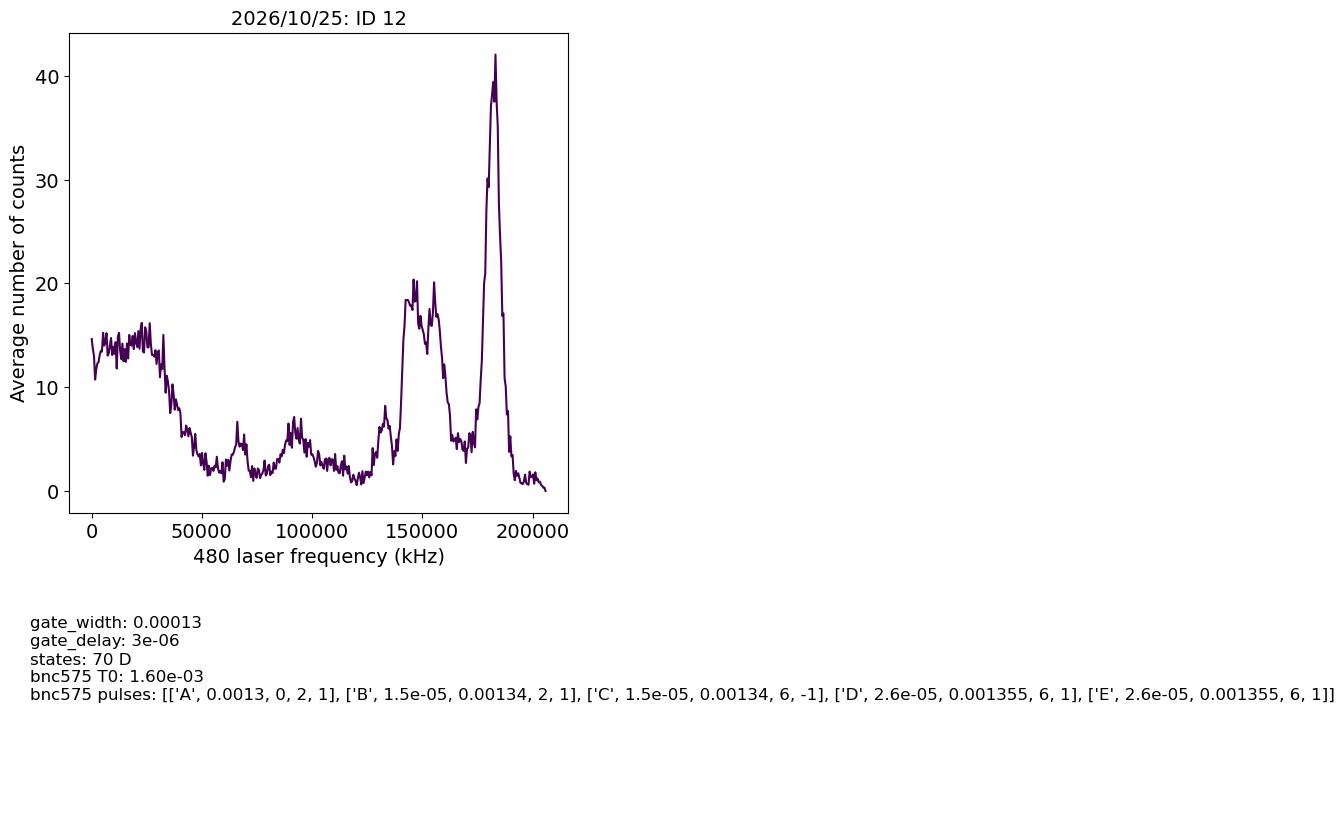

In [50]:
# plot and save results
ps.Plot2D(x = x_list*stride*freq_factor, y = None, Z = results,
          xlabel = "480 laser frequency (kHz)", zlabel = "Average number of counts", notes = notes)

#### 2D maps (voltage scan inside of frequency scan; wide voltage range) and field zeroing

In [41]:
center = center  # center point of frequency scan
stride = 2  # step size
half_width = 300  # step range

# scan list gneration
s_list = np.arange(2*half_width/stride)

# voltage setpoints
vset = np.array([0.4, -0.05, -0.015]) # set all elements to zero when starting the field zeroing, update as new Stark maps are generated 

num_voltages = 31  # number of voltages to test

# voltage arrays for each axis
vx_list = np.linspace(-2.0, 2.0, num_voltages) + vset[0]
vy_list = np.linspace(-2.0, 2.0, num_voltages) + vset[1]
vz_list = np.linspace(-2.0, 2.0, num_voltages) + vset[2]

v_list = np.vstack((vx_list, vy_list, vz_list))

# MC channels for each electrode pair
electrode_pair = [[10,11],[6,7],[0,1]]

In [42]:
# initialize electrode voltages
mcbox.set_voltage_1chan(channel = 10, voltage = vset[0], bipolar = True, display = True)
mcbox.set_voltage_1chan(channel = 11, voltage = -vset[0], bipolar = True, display = True)

mcbox.set_voltage_1chan(channel = 6, voltage = vset[1], bipolar = True, display = True)
mcbox.set_voltage_1chan(channel = 7, voltage = -vset[1], bipolar = True, display = True)

mcbox.set_voltage_1chan(channel = 0, voltage = 0, bipolar = True, display = True)
mcbox.set_voltage_1chan(channel = 1, voltage = -vset[2], bipolar = True, display = True)

Channel 10 has been set to 0.4 V.
Channel 11 has been set to -0.4 V.
Channel 6 has been set to -0.05 V.
Channel 7 has been set to 0.05 V.
Channel 0 has been set to 0 V.
Channel 1 has been set to -0.0 V.


In [43]:
# voltage scan inside a frequency scan, collect counts from gated counter
start_position = center - half_width

stark_map = []

# electrode pair to check; i = 0,1,2 for x,y,z
i = 2

test_voltages = generate_test_voltages(v_list[i])
print('Voltages to test: \n {}'.format(test_voltages))

print('Now checking axis {}'.format(i))
weeder.move(header = "A", position = start_position - 100)
weeder.move(header = "A", position = start_position)

# s = time.perf_counter()
# print('start:',s)

for s in s_list:
    for j in range(stride):
            weeder.step("A", "+")
    print(f"Now checking step: {s}", end = "\r", flush = True)
    
    results = []
    for v_s in test_voltages:
        # scan voltage
        if electrode_pair[i][0] == 0:
            mcbox.set_voltage_1chan(channel = electrode_pair[i][0], voltage = 0, bipolar = True, display = False)
        else:
            mcbox.set_voltage_1chan(channel = electrode_pair[i][0], voltage = v_s, bipolar = True, display = False)
        mcbox.set_voltage_1chan(channel = electrode_pair[i][1], voltage = -v_s, bipolar = True, display = False)
        time.sleep(0.01)
        sr400.count_reset()
        result = np.mean(sr400.read_entire_counts(counter = "A", length = cycle_number))
        results.append(result)
    
    stark_map.append(results)

# e = time.perf_counter()
# print('end:',e)
# print('Time elapsed: {} seconds'.format(e-s))

Voltages to test: 
 [-2.         -1.86666667 -1.73333333 -1.6        -1.46666667 -1.33333333
 -1.2        -1.06666667 -0.93333333 -0.8        -0.66666667 -0.53333333
 -0.4        -0.26666667 -0.13333333  0.          0.13333333  0.26666667
  0.4         0.53333333  0.66666667  0.8         0.93333333  1.06666667
  1.2         1.33333333  1.46666667  1.6         1.73333333  1.86666667
  2.        ]
Now checking axis 2
start at 4300 --> 3600.0 --> 3600
Old position: 4300
New position: 3600
start at 3600 --> 3700.0 --> 3700
Old position: 3600
New position: 3700
Now checking step: 299.0

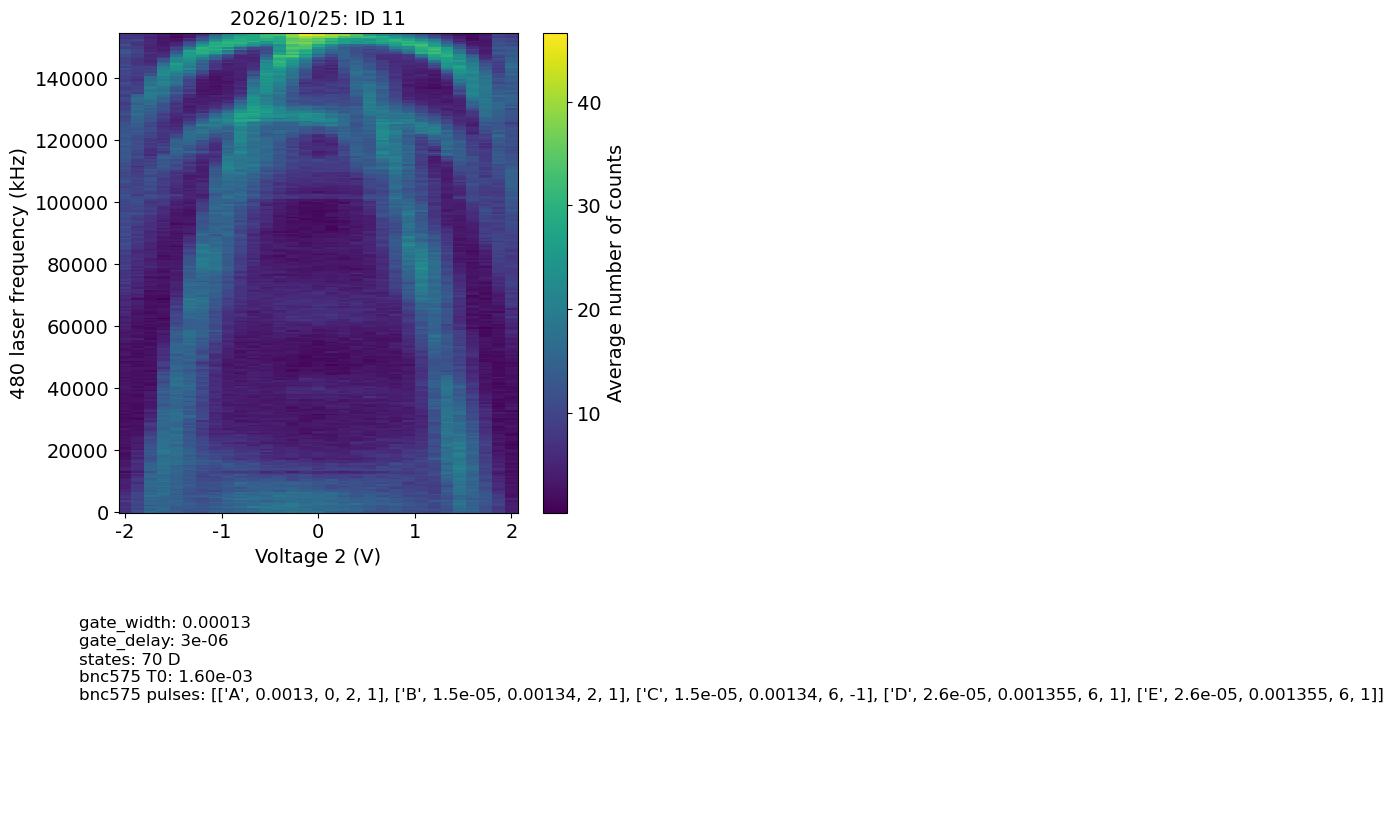

In [44]:
# plot results
ps.Plot3D(x = test_voltages, y = s_list*stride*freq_factor, Z = np.array(stark_map).T,
          xlabel = f"Voltage {i} (V)", ylabel = "480 laser frequency (kHz)", zlabel = "Average number of counts", notes = notes)

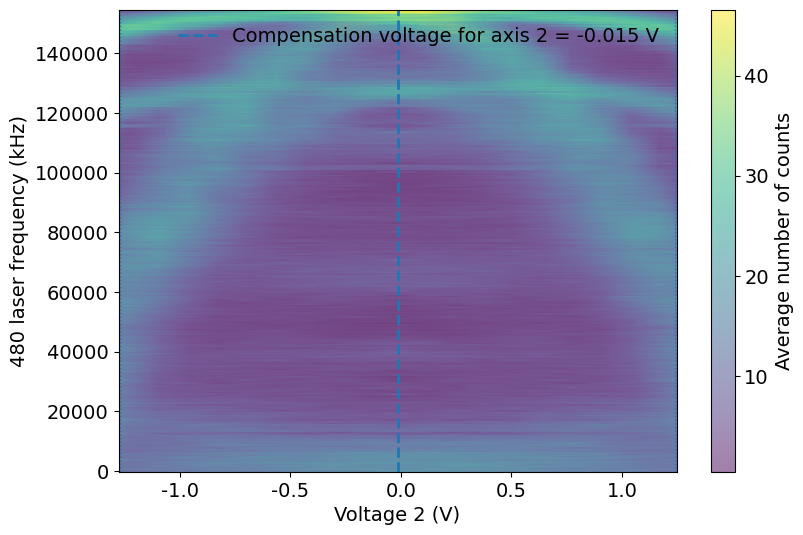

Estimated compensation voltage for axis 2: -0.015 V
Automatically selected comparison half-width: 1.256 V
Local center spread across neighboring widths: 0.001 V


-0.014717434869739532

In [46]:
# perform field zeroing
date = "2026/10/25"
plot_id = 11
symmetry_search(date, plot_id, axis = i, half_width = "auto", plot_best = True, plot_all = False)

### Shut down instrumentation

In [ ]:
# reset voltages to zero
vset = np.array([0.0,0.0,0.0])
mcbox.set_voltage_Nchan(channels = [0,1,6,7,10,11], voltages = [0,-vset[2],vset[1],-vset[1],vset[0],-vset[0]], bipolar = True)

In [ ]:
# save current stepper motor position
weeder.save(header = "A", query = True)

In [ ]:
# OPTIONAL: disables pulses from BNC box (can also be done by pressing RUN/STOP button or individual channel buttons on device)
bnc575.disable_all()

In [ ]:
# OPTIONAL: disarms the pulse generator (can also be done by pressing RUN/STOP button on device)
bnc575.disarm_all()

In [ ]:
# OPTIONAL: used to reset photon counter (can also be done by pressing STOP button on device)
sr400.count_reset()

In [ ]:
# disconnect from pulse generator
bnc575.pyvisa.close()

In [ ]:
# disconnect from SRS photon counter
sr400.pyvisa.close()